# Importing packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from collections import Counter
from sklearn.datasets import make_classification
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Preprocessing data

## Initial data cleaning

In [2]:
df = pd.read_csv('../Data/Thyroid_Diff.csv')
df.head(3)

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No


In [3]:
df.rename(columns={'Hx Smoking' : 'Smoking History',
                   'Hx Radiothreapy' : 'Radiotherapy History',
                   'Pathology' : 'Types of cancer',
                   'T' : 'Tumor class',
                   'N' : 'Nodal class',
                   'M': 'Metastasis class',
                   'Stage' : 'Cancer stage'}, inplace=True)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Age                   383 non-null    int64
 1   Gender                383 non-null    str  
 2   Smoking               383 non-null    str  
 3   Smoking History       383 non-null    str  
 4   Radiotherapy History  383 non-null    str  
 5   Thyroid Function      383 non-null    str  
 6   Physical Examination  383 non-null    str  
 7   Adenopathy            383 non-null    str  
 8   Types of cancer       383 non-null    str  
 9   Focality              383 non-null    str  
 10  Risk                  383 non-null    str  
 11  Tumor class           383 non-null    str  
 12  Nodal class           383 non-null    str  
 13  Metastasis class      383 non-null    str  
 14  Cancer stage          383 non-null    str  
 15  Response              383 non-null    str  
 16  Recurred           

In [5]:
print(df['Adenopathy'].unique())
print(df['Risk'].unique())

<StringArray>
['No', 'Right', 'Extensive', 'Left', 'Bilateral', 'Posterior']
Length: 6, dtype: str
<StringArray>
['Low', 'Intermediate', 'High']
Length: 3, dtype: str


In [6]:
# Ordinal encoding

risk_mapping = {'Low': 0, 'Intermediate': 1, 'High': 2}
df['Risk'] = df['Risk'].map(risk_mapping)

stage_mapping = {'I': 1, 'II': 2, 'III': 3, 'IVA': 4, 'IVB': 5, 'IVC': 6}
df['Cancer stage'] = df['Cancer stage'].map(stage_mapping)

In [7]:
# Binary mapping

df['Gender'] = df['Gender'].map({'F': 0, 'M': 1})

yes_no_cols = ['Smoking', 'Smoking History', 'Radiotherapy History', 'Recurred']
for col in yes_no_cols:
    df[col] = df[col].map({'No': 0, 'Yes': 1})

In [8]:
# One-hot encoding (for multi-class unordered variables)

nominal_columns = [
    'Thyroid Function', 
    'Physical Examination',
    'Adenopathy',
    'Types of cancer', 
    'Focality', 
    'Tumor class', 
    'Nodal class', 
    'Metastasis class'
]

df = pd.get_dummies(df, columns=nominal_columns, drop_first=True)

In [9]:
# Encoding target

le = LabelEncoder()
df['Response'] = le.fit_transform(df['Response'])

In [11]:
df.isnull().sum()

Age                                                 0
Gender                                              0
Smoking                                             0
Smoking History                                     0
Radiotherapy History                                0
Risk                                                0
Cancer stage                                        0
Response                                            0
Recurred                                            0
Thyroid Function_Clinical Hypothyroidism            0
Thyroid Function_Euthyroid                          0
Thyroid Function_Subclinical Hyperthyroidism        0
Thyroid Function_Subclinical Hypothyroidism         0
Physical Examination_Multinodular goiter            0
Physical Examination_Normal                         0
Physical Examination_Single nodular goiter-left     0
Physical Examination_Single nodular goiter-right    0
Adenopathy_Extensive                                0
Adenopathy_Left             

In [12]:
df.duplicated().sum()

np.int64(19)

In [13]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

## First data visualisation

In [14]:
df.describe()

,Age,Gender,Smoking,Smoking History,Radiotherapy History,Risk,Cancer stage,Response,Recurred
count,364.00000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000
mean,41.25000,0.195055,0.134615,0.076923,0.019231,0.456044,1.255495,1.604396,0.296703
std,15.31436,0.396788,0.341782,0.266836,0.137524,0.651966,0.791203,0.931590,0.457433
min,15.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,30.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
50%,38.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
75%,52.00000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,2.250000,1.000000
max,82.00000,1.000000,1.000000,1.000000,1.000000,2.000000,5.000000,3.000000,1.000000


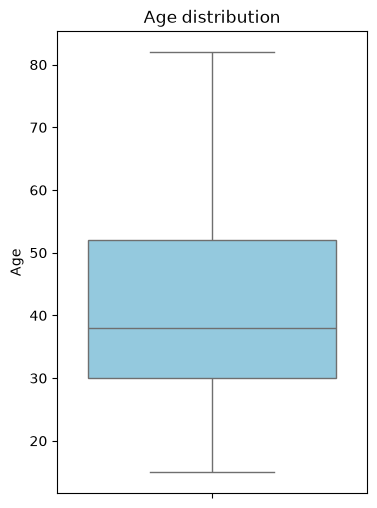

In [50]:
plt.figure(figsize=(4, 6))
plt.title('Age distribution')

sns.boxplot(data=df['Age'], color='skyblue')

plt.show()

1. The people in the sample are quite old (mean around 40, 50% are between 30 and 50 y.o.)
2. Most of them are women (near 80%)
3. There are little clue smoking is linked to tyroid cancer
4. Rate of recovery is large (around 70%)

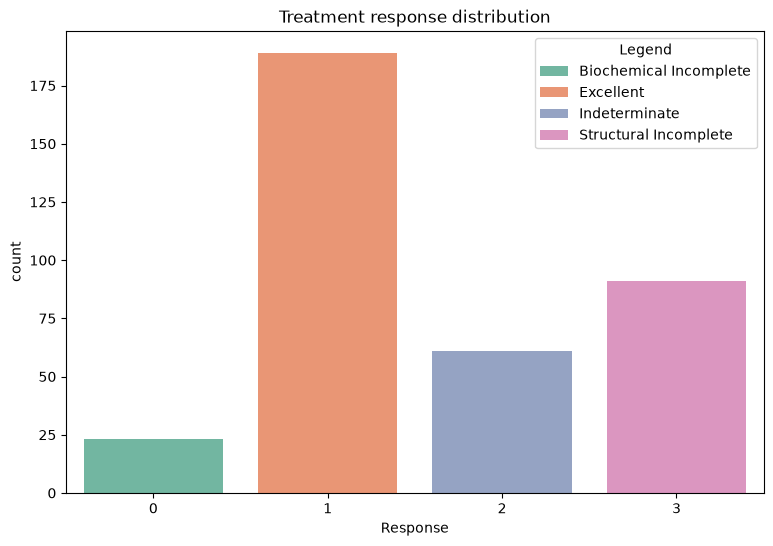

In [59]:
plt.figure(figsize=(9, 6))
plt.title('Treatment response distribution')

sns.countplot(data=df, x='Response', hue = 'Response', palette='Set2')

response_labels = [
    'Biochemical Incomplete',
    'Excellent',
    'Indeterminate',
    'Structural Incomplete'
]
plt.legend(labels = response_labels, title = 'Legend')

plt.show()

Treatment response distribution tells us ~52% of the people get an excellent response to treatment and 48% have some kind of problem with it.
- Biochemical Incomplete (~6%) : Imaging tests show no abnormalities, but tumour markers in the blood remain detectable or abnormal. The disease is still active at a molecular level.
- Indeterminate (~17%) : The clinical or blood test results are inconclusive. This requires longer-term monitoring, but it is not yet clear whether the treatment has failed.
- Structural Incomplete (~25%) : The treatment is unsuitable or has failed. There is still physical and visible evidence of the disease.

### Data visualisation insights

These graphs have enabled us to gain a better understanding of the profile within the sample. We now need to scale all the variables and to address class imbalances in ``Response``. Looking at the above graph, we also clearly notice classes imbalances within our target ``Response``. We may consider one or more of those solutions :
- Using class weight balance within the parameters of the models
- Grouping small and near-clinical cases classes
- Resampling methods (i.e. SMOTE)

## Train/test split and scaling

In [17]:
# X and Y separation
X = df.drop(columns=['Response'])
y = df['Response']

In [18]:
# Test and train data separation : as previous investigation suggested, Response being so imbalanced, we have to stratify the separation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
# Scaling
std_scaler = StandardScaler()
std_scaler.set_output(transform="pandas")

X_train = std_scaler.fit_transform(X_train)
X_test = std_scaler.transform(X_test)

## Second data visualisation

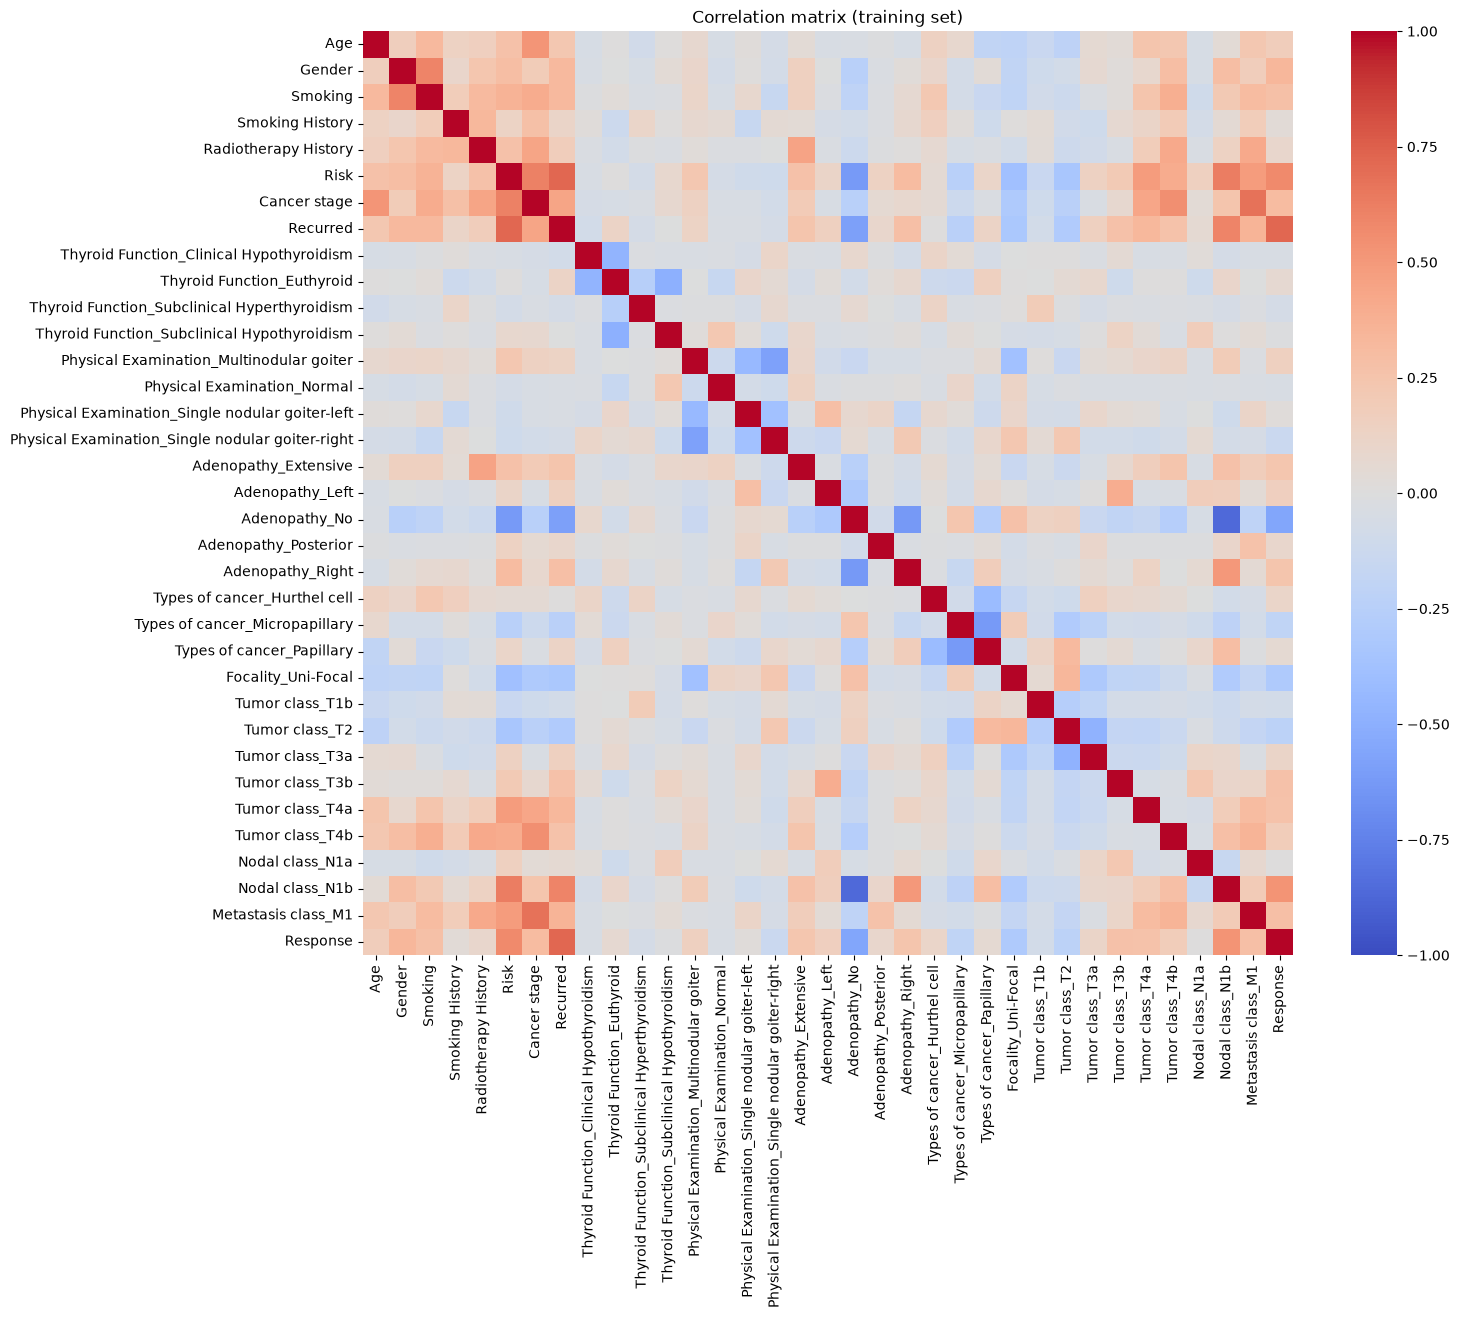

In [20]:
train_data = pd.concat([X_train, y_train], axis = 1)

plt.figure(figsize=(15, 12))
sns.heatmap(train_data.corr(), cmap = 'coolwarm', vmin = -1, vmax = 1)
plt.title('Correlation matrix (training set)')
plt.show()

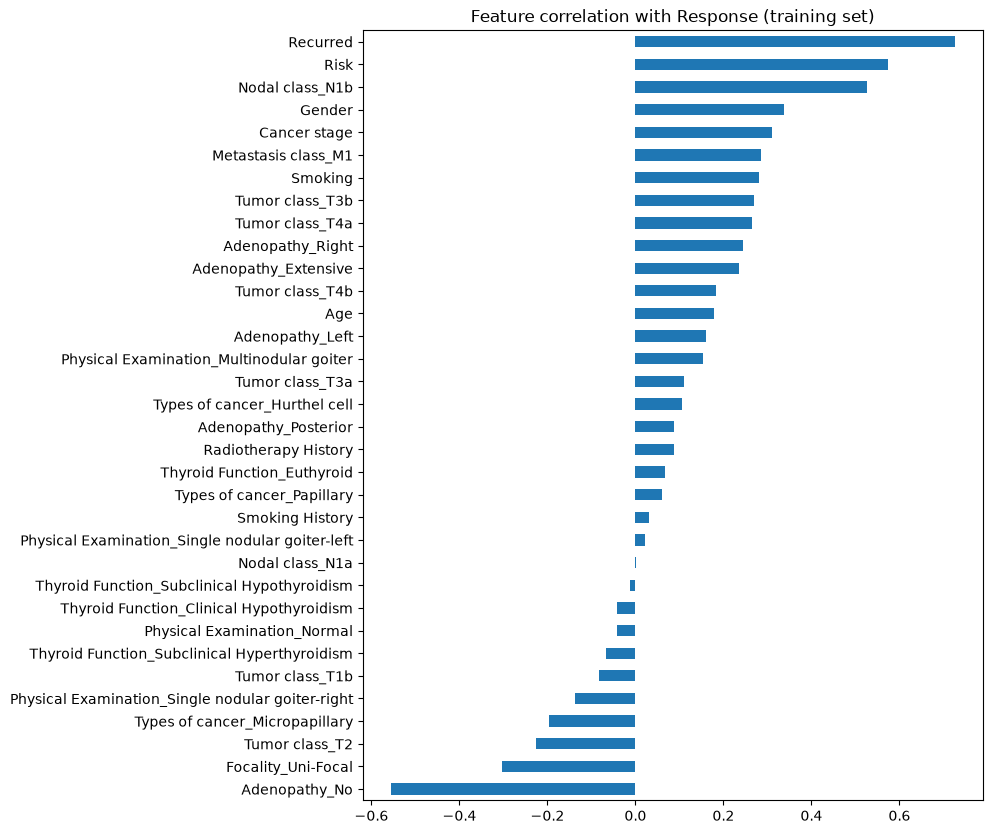

In [21]:
plt.figure(figsize=(8, 10))
train_data.corr()['Response'].sort_values().drop('Response').plot(kind = 'barh')
plt.title('Feature correlation with Response (training set)')
plt.show()

The clinical response (``Response``) is most strongly associated with recurrence (``Recurred``), risk assessment (``Risk``) and severe lymph node involvement (``Nodal class_N1b``), followed by tumour stage and metastases. 

The absence of lymph node involvement (``Adenopathy_No``) and a unifocal nature (``Focality_Uni-Focal``) emerge as the most decisive favourable markers, showing the strongest negative correlations. Finally, this one-dimensional analysis confirms the non-predictive nature of thyroid function tests and isolated local physical examinations, whose coefficients remain virtually zero, thereby confirming their limited usefulness in modelling this clinical outcome.

Direct implications for the model:
- Multicollinearity and redundancy: ``Smoking`` and ``Smoking History`` are duplicates. If using a linear or logistic model, remove one of the two.   
- Effect of one-hot encoding: the strong negative correlations within the same category (e.g. ``Adenopathy_No`` compared with other types of adenopathy) are mechanical. Consider removing a reference modality (drop_first=True) if decision trees are not being used.

# Model

## Preliminary considerations

As there's so many classes imbalances, we may need to consider the following solutions :

1. Ponderate it within the algorithms we use :
- Logistic regression (Lasso/ElasticNet): ``LogisticRegression(penalty=“l1”, solver=“saga”, class_weight=“balanced”)``
- Random Forest: ``RandomForestClassifier(class_weight=“balanced”)``
- Pass ``class_weight='balanced'`` in any estimator of my choice

2. Resampling techniques (ONLY if step no. 1 isn't enough) using the ``imbalanced-learn`` library:
- SMOTE (synthetic minority class oversampling) only to ``X_train`` and ``y_train``

3. Choosing the right evaluation metrics :
- The normalised confusion matrix ``(ConfusionMatrixDisplay.from_estimator(..., normalize=“true”))`` to check the detection rate class by class
- The macro F1-score ``(f1_score(y_test, y_pred, average=“macro”))``, which gives equal weight to each class regardless of its frequency
- Any other evaluation method not sensible to imbalances

## Linear SVC model

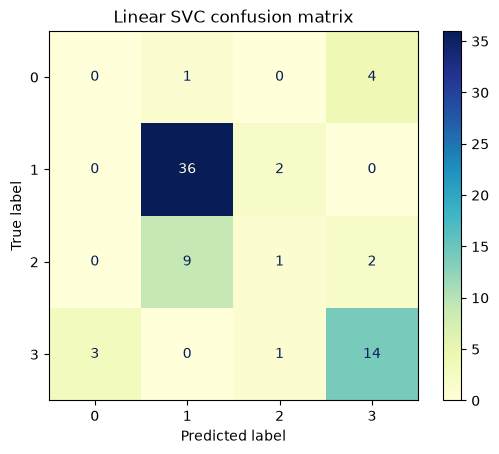

In [22]:
# Model
lsvc = LinearSVC(class_weight='balanced', random_state=0, max_iter=5000) # may nedd to change max_iter

# Training
lsvc.fit(X_train, y_train)

# Prediction
y_pred = lsvc.predict(X_test)

lsvc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
lsvc_cm.plot(cmap = 'YlGnBu')
plt.title('Linear SVC confusion matrix')
plt.show()

Results interpretation :
- Class 0 : The model is bad, 0/5 results were well-classified
- Class 1 : The model performs well, 36/38 results were well-classified, the model handles it well because its the majority of the dataset
- Class 2 : 1/12 were well-classified
- Class 3 : 14/18 were well-classified

The model suffers from the class imbalances even though we've activated the balance option within the classifier. Hence, we'll just continue with another model.

## Kneighbours classifier

In [23]:
# Train a k-NN classifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[0,1,2,3]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [24]:
# Prediction
y_pred = knn.predict(X_test)

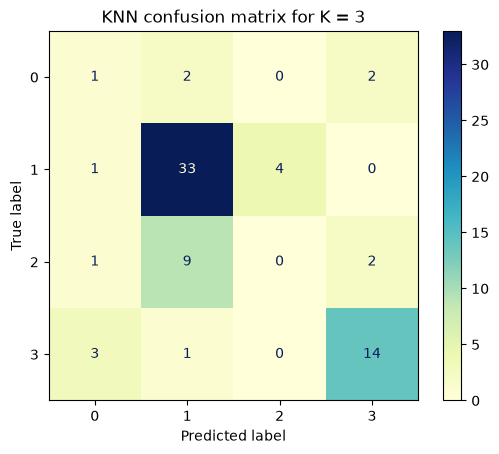

In [25]:
# Evaluation
knn_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
knn_cm.plot(cmap = 'YlGnBu')
plt.title('KNN confusion matrix for K = 3')
plt.show()

The results look quite the same as for linear SVC for now. We may need to look for a better $K$.

In [26]:
for K in range(1,20) :

    # Train a k-NN classifier
    knn = KNeighborsClassifier(n_neighbors = K)
    knn.fit(X_train, y_train)

    # Prediction
    y_pred = knn.predict(X_test)

    # Evaluation
    trace = np.trace(confusion_matrix(y_test, y_pred))
    print(f'Trace of the confusion matrix is {trace} for K = {K}.')

Trace of the confusion matrix is 45 for K = 1.
Trace of the confusion matrix is 43 for K = 2.
Trace of the confusion matrix is 48 for K = 3.
Trace of the confusion matrix is 52 for K = 4.
Trace of the confusion matrix is 53 for K = 5.
Trace of the confusion matrix is 54 for K = 6.
Trace of the confusion matrix is 52 for K = 7.
Trace of the confusion matrix is 52 for K = 8.
Trace of the confusion matrix is 52 for K = 9.
Trace of the confusion matrix is 53 for K = 10.
Trace of the confusion matrix is 53 for K = 11.
Trace of the confusion matrix is 52 for K = 12.
Trace of the confusion matrix is 54 for K = 13.
Trace of the confusion matrix is 52 for K = 14.
Trace of the confusion matrix is 53 for K = 15.
Trace of the confusion matrix is 53 for K = 16.
Trace of the confusion matrix is 53 for K = 17.
Trace of the confusion matrix is 54 for K = 18.
Trace of the confusion matrix is 53 for K = 19.


It seems the best confusion matrix we get was $K = 6$, $K = 13$ or $K = 18$.

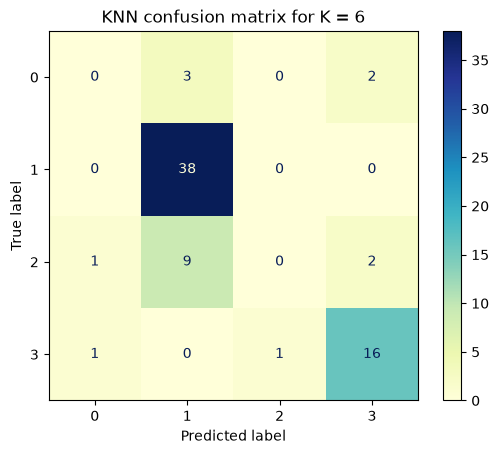

In [27]:
K = 6

# Train a k-NN classifier
knn = KNeighborsClassifier(n_neighbors = K)
knn.fit(X_train, y_train)

# Prediction
y_pred = knn.predict(X_test)

# Evaluation
knn_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
knn_cm.plot(cmap = 'YlGnBu')
plt.title('KNN confusion matrix for K = 6')
plt.show()

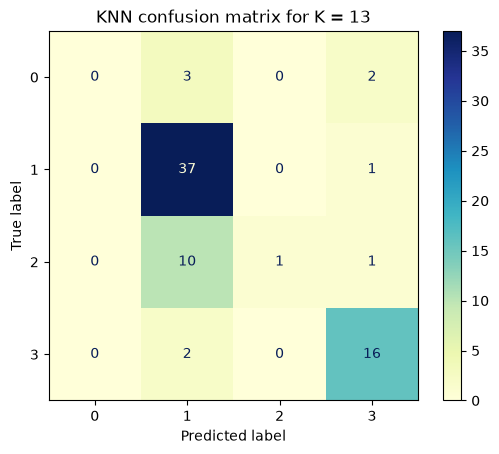

In [28]:
K = 13

# Train a k-NN classifier
knn = KNeighborsClassifier(n_neighbors = K)
knn.fit(X_train, y_train)

# Prediction
y_pred = knn.predict(X_test)

# Evaluation
knn_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
knn_cm.plot(cmap = 'YlGnBu')
plt.title('KNN confusion matrix for K = 13')
plt.show()

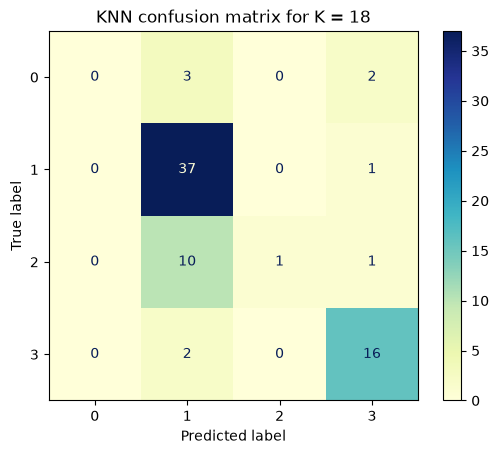

In [29]:
K = 18

# Train a k-NN classifier
knn = KNeighborsClassifier(n_neighbors = K)
knn.fit(X_train, y_train)

# Prediction
y_pred = knn.predict(X_test)

# Evaluation
knn_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
knn_cm.plot(cmap = 'YlGnBu')
plt.title('KNN confusion matrix for K = 18')
plt.show()

None of the $K$ parameters gave us a satisfactory result. The model still can't handle the classes imbalances. We hence need to consider SVC and/or ensemble classifiers.

## SVC model

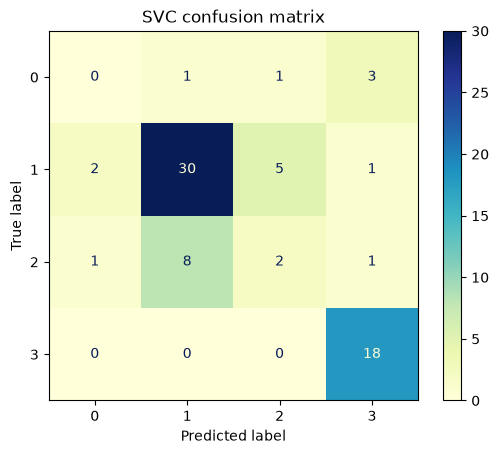

In [30]:
# Model
svc = SVC(class_weight='balanced', random_state=0, max_iter=5000)

# Training
svc.fit(X_train, y_train)

# Prediction
y_pred = svc.predict(X_test)

svc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
svc_cm.plot(cmap = 'YlGnBu')
plt.title('SVC confusion matrix')
plt.show()

The class imbalances problem still occurs with this model. We'll then give a shot to a Random Forest Classifier.

## Random Forest Classifier

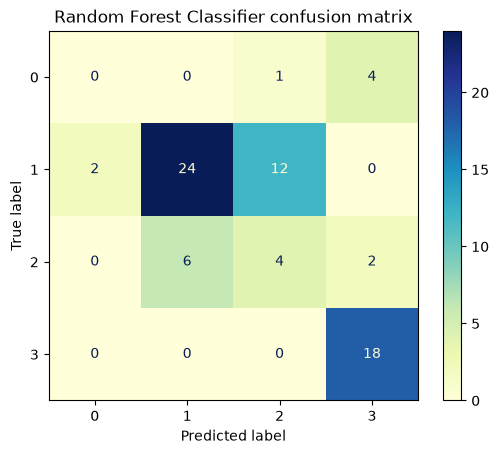

In [31]:
# Model
rfc = RandomForestClassifier(class_weight='balanced', random_state=42)

# Training
rfc.fit(X_train, y_train)

# Prediction
y_pred = rfc.predict(X_test)

rfc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
rfc_cm.plot(cmap = 'YlGnBu')
plt.title('Random Forest Classifier confusion matrix')
plt.show()

The results are still not satisfactory. Although there have been improvements in classes 2 and 3, class 0 still has a recall rate of 0 per cent and results for class 1 have deteriorated. Class 0 comprises only 5 instances in the test set. Even with a ensemble model, the algorithm does not have enough distinct examples to learn its signature without confusing it with class 3.

Hence, we're considering SMOTE for the next steps before testing again with a Random Forest Classifier.

## SMOTE

In [32]:
np.shape(train_data)

(291, 35)

In [33]:
sm = SMOTE(k_neighbors = 3, random_state = 42)
X_res, y_res = sm.fit_resample(X_train, y_train)
print('Resampled dataset shape %s' % Counter(y_res))

np.shape(y_test)

Resampled dataset shape Counter({1: 151, 2: 151, 3: 151, 0: 151})


(73,)

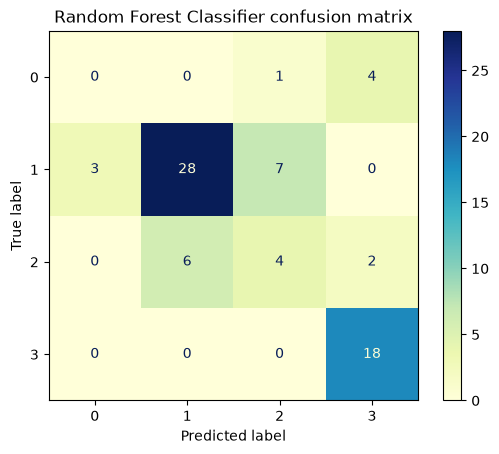

In [34]:
# Model
rfc = RandomForestClassifier(class_weight='balanced', random_state=42)

# Training
rfc.fit(X_res, y_res)

# Prediction
y_pred = rfc.predict(X_test)

rfc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
rfc_cm.plot(cmap = 'YlGnBu')
plt.title('Random Forest Classifier confusion matrix')
plt.show()

None of the approaches discussed before worked for better predicting class 0 *(Biochemical Incomplete)*. The lack of data for this variable is undoubtedly the cause. We hence need to merge it with a near-clinical classe, class 3 *(Structural Incomplete)*, to create a new category *Incomplete*, which should resolve the volume issue. Still, the model struggles to correclty predict the 2nd class as well. This is probably due to the lack of data as well ($n = 12$ for this class).

## Merging classes

In [35]:
y_train = y_train.replace(to_replace = 3, value = 0) ;
3 in y_train.values

False

In [36]:
y_test = y_test.replace(to_replace = 3, value = 0) ;
3 in y_test.values

False

## Training with class balance parameter

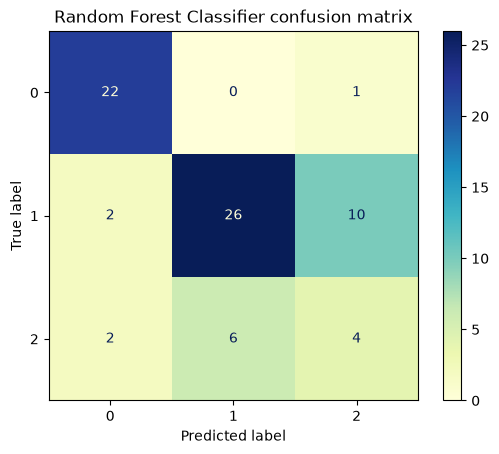

In [37]:
# Model
rfc = RandomForestClassifier(class_weight='balanced', random_state=42)

# Training
rfc.fit(X_train, y_train)

# Prediction
y_pred = rfc.predict(X_test)

rfc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
rfc_cm.plot(cmap = 'YlGnBu')
plt.title('Random Forest Classifier confusion matrix')
plt.show()

The model is doing well beter at predicting the new merged class. Still, the 2nd class predictions still are an issue and as we balanced the classes, the first class predictions should be improved.

Note for myself : at the very end, I am supposed to merge train and test data ? For +++ data ?